# 06_kpi_desde_ficheros

**Origen:** `06_kpi_desde_ficheros.ktr` (transformación de Pentaho)  
**Fecha:** 2026-10-27  
**Biblioteca:** PySpark  
**Cobertura:** Steps: 17 (17 exactos, 0 aproximados, 0 a completar)

*Generado por Pentaho Live a partir de la transformación.*

## Cómo correrlo

1. Instala las bibliotecas: `pip install pyspark pandas openpyxl matplotlib`
   PySpark necesita Java 17 o posterior (JAVA_HOME).
2. Deja este archivo en la carpeta del .ktr (las rutas relativas parten de ahí).

In [1]:
from pyspark.sql import SparkSession, functions as F, types as T, Window
import os
import pandas as pd
import json

_builder = SparkSession.builder.appName("06_kpi_desde_ficheros")
if os.name == "nt":  # Windows: Spark local en localhost (un nombre de equipo con _ lo rompe)
    _builder = _builder.config("spark.driver.host", "localhost").config("spark.driver.bindAddress", "127.0.0.1")
spark = _builder.getOrCreate()

# carpeta del script (o del notebook): la misma que la del .ktr
AQUI = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
VARS = {
    "Internal.Transformation.Filename.Directory": os.environ.get("Internal.Transformation.Filename.Directory", AQUI),
    "Internal.Entry.Current.Directory": os.environ.get("Internal.Entry.Current.Directory", AQUI),
    "Internal.Transformation.Name": "06_kpi_desde_ficheros",
}


def _jsonpath(doc, ruta):
    """Valores de un JSONPath sencillo ($.a.b, $..a, [*], [n], ['x']) en orden de documento."""
    import re
    pasos = re.findall(r"\.\.[^.\[]+|\.[^.\[]+|\[[^\]]*\]", ruta.lstrip("$"))
    nodos = [doc]
    for p in pasos:
        sig = []
        if p.startswith(".."):
            clave = p[2:]
            def bajar(n):
                if isinstance(n, dict):
                    if clave in n:
                        sig.append(n[clave])
                    for v in n.values():
                        bajar(v)
                elif isinstance(n, list):
                    for v in n:
                        bajar(v)
            for n in nodos:
                bajar(n)
        elif p in (".*", "[*]"):
            for n in nodos:
                sig.extend(n if isinstance(n, list) else n.values() if isinstance(n, dict) else [])
        elif p.startswith("["):
            k = p[1:-1].strip("'\"")
            for n in nodos:
                if isinstance(n, list) and k.lstrip("-").isdigit() and -len(n) <= int(k) < len(n):
                    sig.append(n[int(k)])
                elif isinstance(n, dict) and k in n:
                    sig.append(n[k])
        else:
            for n in nodos:
                if isinstance(n, dict) and p[1:] in n:
                    sig.append(n[p[1:]])
        nodos = sig
    return nodos


def pdi_rachas(df, claves):
    """Añade _orden (orden de llegada) y _racha: el número de racha de filas seguidas con las mismas claves, como agrupa PDI (compara cada fila con la anterior; nulo = nulo)."""
    df = df.withColumn("_orden", F.monotonically_increasing_id())
    w = Window.orderBy("_orden")
    igual = F.lag("_orden").over(w).isNotNull()
    for c in claves:
        igual = igual & F.col(c).eqNullSafe(F.lag(c).over(w))
    return df.withColumn("_racha", F.sum(F.when(igual, 0).otherwise(1)).over(w))


def _numero_texto(serie, decimales, fijos, agrupar, sep_decimal=".", sep_grupo=","):
    """Número a texto como una máscara de Java (#,##0.00): decimales, mínimos fijos y separadores."""
    def f(v):
        if pd.isna(v):
            return None
        t = format(float(v), ("," if agrupar else "") + f".{decimales}f")
        if fijos < decimales and "." in t:
            ent, dec = t.split(".")
            dec = dec[:fijos] + dec[fijos:].rstrip("0")
            t = ent + ("." + dec if dec else "")
        return t.replace(",", "\0").replace(".", sep_decimal).replace("\0", sep_grupo)
    return serie.map(f)


def _escribir_texto(df, ruta, sep=";", encierro='"', forzar=False, cabecera=True, anexar=False,
                    codificacion="utf-8", fin="\r\n", textos=()):
    """Escribe df como el Text file output de PDI: encierra los campos de texto (siempre si forzar;
    si no, sólo los que llevan el separador, el encierro o un salto de línea) y pone la cabecera si el
    archivo es nuevo."""
    nuevo = not (anexar and os.path.exists(ruta) and os.path.getsize(ruta) > 0)
    columnas = []
    for c in df.columns:
        s = df[c].astype(object).map(lambda v: "" if v is None or pd.isna(v) else str(v))
        if c in textos and encierro:
            if forzar:
                poner = s != ""
            else:
                poner = s.str.contains(sep, regex=False) | s.str.contains(encierro, regex=False) \
                    | s.str.contains("\n", regex=False)
            s = s.where(~poner, encierro + s.str.replace(encierro, encierro * 2, regex=False) + encierro)
        columnas.append(s)
    with open(ruta, "a" if anexar else "w", encoding=codificacion, newline="") as f:
        if cabecera and nuevo:
            f.write(sep.join(encierro + str(c) + encierro if forzar and c in textos else str(c)
                             for c in df.columns) + fin)
        if columnas:
            lineas = columnas[0]
            for s in columnas[1:]:
                lineas = lineas + sep + s
            f.write("".join(linea + fin for linea in lineas))


def _nombre_salida(nombre, extension="", fecha="", parte=None):
    """Nombre del archivo como lo arma PDI: nombre[fecha][_parte].extensión."""
    import datetime
    r = nombre + (datetime.datetime.now().strftime(fecha) if fecha else "")
    if parte is not None:
        r += f"_{parte}"
    return r + ("." + extension if extension else "")

import matplotlib.pyplot as plt
import pandas as pd

## 1. Leer ventas (CSV)

`CsvInput`

Lee ventas_2026_09.csv (8 campos)

> Nota: Como en PDI, el texto vacío se lee como nulo.

In [2]:
archivo_leer_ventas_csv = f"{VARS['Internal.Entry.Current.Directory']}/../datos/ventas_2026_09.csv"
df_leer_ventas_csv = spark.read.csv(archivo_leer_ventas_csv, sep=";", quote="\"", header=True, encoding="UTF-8",
    schema="`id_ticket` STRING, `linea` STRING, `fecha` STRING, `id_tienda` STRING, `codigo_producto` STRING, `cantidad` STRING, `precio_unitario` STRING, `metodo_pago` STRING")
df_leer_ventas_csv = df_leer_ventas_csv.withColumns({
    "linea": F.col("linea").cast("long"),
    "cantidad": F.col("cantidad").cast("long"),
})
df_leer_ventas_csv.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|           1.80|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|           1,80|   efectivo|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|           2.80|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|           1.80|   Tarjeta |
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|           2.10|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|           3.20|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|           3.00|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|           3.20| 

## 2. Estandarizar textos

`StringOperations`

Limpia campos de texto

In [3]:
df_estandarizar_textos = (df_leer_ventas_csv
    .withColumn("id_tienda", F.upper(F.trim(F.col("id_tienda"))))
    .withColumn("codigo_producto", F.upper(F.trim(F.col("codigo_producto"))))
    .withColumn("metodo_pago", F.upper(F.trim(F.col("metodo_pago")))))
df_estandarizar_textos.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|           1.80|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|           1,80|   EFECTIVO|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|           2.80|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|           1.80|    TARJETA|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|           2.10|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|           3.20|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|           3.00|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|           3.20| 

## 3. Normalizar precio

`ReplaceString`

Limpia campos de texto

In [4]:
df_normalizar_precio = (df_estandarizar_textos
    .withColumn("precio_unitario", F.regexp_replace(F.col("precio_unitario"), "(?i),", ".")))
df_normalizar_precio.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|           1.80|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|           1.80|   EFECTIVO|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|           2.80|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|           1.80|    TARJETA|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|           2.10|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|           3.20|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|           3.00|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|           3.20| 

## 4. Convertir precio a número

`SelectValues`

Cambia el tipo de 1 campos

In [5]:
df_convertir_precio_a_numero = df_normalizar_precio
df_convertir_precio_a_numero = df_convertir_precio_a_numero.withColumn("precio_unitario", F.col("precio_unitario").cast("double"))
df_convertir_precio_a_numero.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|            3.0|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|            3.2| 

## 5. Leer productos (Excel)

`ExcelInput`

Lee productos.xlsx (4 campos)

> Nota: Spark no lee Excel: se lee con pandas (openpyxl) y se pasa a Spark.

> Nota: Necesita openpyxl (xlsx) o xlrd (xls antiguos).

In [6]:
archivos_leer_productos_excel = [f"{VARS['Internal.Entry.Current.Directory']}/../datos/productos.xlsx"]
partes = []
for archivo in archivos_leer_productos_excel:
    for hoja, fila0, col0 in [("Productos", 0, 0)]:
        parte = pd.read_excel(archivo, sheet_name=hoja, header=None, skiprows=fila0 + 1, dtype=object)
        parte = parte.iloc[:, col0:col0 + 4]
        parte.columns = ["codigo_producto", "nombre", "categoria", "precio_venta"][:parte.shape[1]]
        partes.append(parte)
pdf_leer_productos_excel = pd.concat(partes, ignore_index=True)
pdf_leer_productos_excel = pdf_leer_productos_excel.dropna(how="all", subset=["codigo_producto", "nombre", "categoria", "precio_venta"]).reset_index(drop=True)
pdf_leer_productos_excel["codigo_producto"] = pdf_leer_productos_excel["codigo_producto"].astype("string")
pdf_leer_productos_excel["nombre"] = pdf_leer_productos_excel["nombre"].astype("string")
pdf_leer_productos_excel["categoria"] = pdf_leer_productos_excel["categoria"].astype("string")
pdf_leer_productos_excel["precio_venta"] = pd.to_numeric(pdf_leer_productos_excel["precio_venta"]).astype("float64")
df_leer_productos_excel = spark.createDataFrame(pdf_leer_productos_excel.astype(object).where(pdf_leer_productos_excel.notna(), None))
df_leer_productos_excel.show(10)

+---------------+--------------+----------+------------+
|codigo_producto|        nombre| categoria|precio_venta|
+---------------+--------------+----------+------------+
|        CAF-001|      Espresso|      café|         1.5|
|        CAF-002|       Cortado|      CAFÉ|         1.7|
|        CAF-003|Café con leche|      CAFÉ|         2.1|
|        CAF-004|    Cappuccino|      Café|         2.6|
|        CAF-005|         Latte|      Café|         2.8|
|        CAF-006|    Flat white|      Café|         3.0|
|        CAF-007|    Americano |      café|         1.9|
|        CAF-008|   Café bombón|      Café|         2.2|
|        INF-001|      Té verde|Infusiones|         2.0|
|        INF-002|      Té negro|infusiones|         2.0|
+---------------+--------------+----------+------------+
only showing top 10 rows


## 6. Ordenar por ticket y línea

`SortRows`

Ordena por id_ticket, linea

> Nota: Spark no garantiza un orden estable entre filas con la misma clave.

In [7]:
df_ordenar_por_ticket_y_linea = df_convertir_precio_a_numero.orderBy(F.lower(F.col("id_ticket")).asc_nulls_first(), F.col("linea").asc_nulls_first())
df_ordenar_por_ticket_y_linea.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|            3.0|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|            3.2| 

## 7. Leer tiendas (JSON)

`JsonInput`

Lee tiendas.json (2 campos)

> Nota: El JSON se lee con Python y se pasa a Spark (spark.read.json necesita un objeto por línea).

> Nota: _jsonpath cubre los JSONPath habituales; los filtros [?(...)] hay que hacerlos a mano.

In [8]:
def _filas_json(doc):
    cols = {"id_tienda": _jsonpath(doc, "$.tiendas[*].id_tienda"), "nombre": _jsonpath(doc, "$.tiendas[*].nombre")}
    n = max((len(v) for v in cols.values()), default=0)
    return pd.DataFrame({k: (v + [None] * n)[:n] for k, v in cols.items()}, dtype=object)
archivos_leer_tiendas_json = [f"{VARS['Internal.Entry.Current.Directory']}/../datos/tiendas.json"]
partes = []
for archivo in archivos_leer_tiendas_json:
    with open(archivo, encoding="utf-8") as fh:
        parte = _filas_json(json.load(fh))
    partes.append(parte)
pdf_leer_tiendas_json = pd.concat(partes, ignore_index=True)
pdf_leer_tiendas_json = pdf_leer_tiendas_json.astype(object).where(pdf_leer_tiendas_json.notna(), None)
pdf_leer_tiendas_json[["id_tienda", "nombre"]] = pdf_leer_tiendas_json[["id_tienda", "nombre"]].map(lambda v: v if v is None or isinstance(v, str) else json.dumps(v) if isinstance(v, (dict, list)) else str(v).lower() if isinstance(v, bool) else str(v))
df_leer_tiendas_json = spark.createDataFrame(pdf_leer_tiendas_json, "`id_tienda` STRING, `nombre` STRING")
df_leer_tiendas_json = df_leer_tiendas_json.withColumns({
    "id_tienda": F.trim(F.col("id_tienda")),
    "nombre": F.trim(F.col("nombre")),
})
df_leer_tiendas_json.show(10)

+---------+---------+
|id_tienda|   nombre|
+---------+---------+
|      T01| Malasaña|
|      T02| Chamberí|
|      T03|Salamanca|
|      T04|   Retiro|
+---------+---------+



## 8. Estandarizar productos

`StringOperations`

Limpia campos de texto

In [9]:
df_estandarizar_productos = (df_leer_productos_excel
    .withColumn("codigo_producto", F.upper(F.trim(F.col("codigo_producto"))))
    .withColumn("nombre", F.trim(F.col("nombre")))
    .withColumn("categoria", F.initcap(F.trim(F.col("categoria")))))
df_estandarizar_productos.show(10)

+---------------+--------------+----------+------------+
|codigo_producto|        nombre| categoria|precio_venta|
+---------------+--------------+----------+------------+
|        CAF-001|      Espresso|      Café|         1.5|
|        CAF-002|       Cortado|      Café|         1.7|
|        CAF-003|Café con leche|      Café|         2.1|
|        CAF-004|    Cappuccino|      Café|         2.6|
|        CAF-005|         Latte|      Café|         2.8|
|        CAF-006|    Flat white|      Café|         3.0|
|        CAF-007|     Americano|      Café|         1.9|
|        CAF-008|   Café bombón|      Café|         2.2|
|        INF-001|      Té verde|Infusiones|         2.0|
|        INF-002|      Té negro|Infusiones|         2.0|
+---------------+--------------+----------+------------+
only showing top 10 rows


## 9. Eliminar duplicados

`Unique`

Quita duplicados por id_ticket, linea

In [10]:
# PDI compara cada fila con la anterior: sólo quita duplicados SEGUIDOS (entrada ordenada).
d = pdi_rachas(df_ordenar_por_ticket_y_linea, ["id_ticket", "linea"])
d = d.withColumn("_primera", F.col("_orden") == F.min("_orden").over(Window.partitionBy("_racha")))
df_eliminar_duplicados = d.filter("_primera").orderBy("_orden").drop("_orden", "_racha", "_primera")
df_eliminar_duplicados.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|            3.0|    TARJETA|
| TK000005|    1|01/09/2026|      T01|        SAL-004|       2|            3.2| 

## 10. Buscar tienda

`StreamLookup`

Busca en «Leer tiendas (JSON)» por id_tienda

In [11]:
# Si la clave se repite en el flujo de búsqueda, PDI se queda con la última fila.
busca = df_leer_tiendas_json.withColumn("_orden", F.monotonically_increasing_id())
busca = busca.withColumn("_ultima", F.max("_orden").over(Window.partitionBy("id_tienda")))
busca = busca.filter(F.col("_orden") == F.col("_ultima")).select(F.col("id_tienda").alias("_k0"), F.col("nombre").alias("tienda"), F.lit(True).alias("_hay"))
df_buscar_tienda = df_eliminar_duplicados.join(F.broadcast(busca), F.col("id_tienda").eqNullSafe(F.col("_k0")), "left")
df_buscar_tienda = df_buscar_tienda.drop("_k0", "_hay")
df_buscar_tienda.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|  tienda|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|Malasaña|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|Malasaña|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|Malasaña|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|Malasaña|
| TK000004|    2|01/09/2026|      T01|        BEB-001|       1|            3.0|    TARJETA|

## 11. Buscar categoría

`StreamLookup`

Busca en «Estandarizar productos» por codigo_producto

In [12]:
# Si la clave se repite en el flujo de búsqueda, PDI se queda con la última fila.
busca_2 = df_estandarizar_productos.withColumn("_orden", F.monotonically_increasing_id())
busca_2 = busca_2.withColumn("_ultima", F.max("_orden").over(Window.partitionBy("codigo_producto")))
busca_2 = busca_2.filter(F.col("_orden") == F.col("_ultima")).select(F.col("codigo_producto").alias("_k0"), F.col("categoria").alias("categoria"), F.lit(True).alias("_hay"))
df_buscar_categoria = df_buscar_tienda.join(F.broadcast(busca_2), F.col("codigo_producto").eqNullSafe(F.col("_k0")), "left")
df_buscar_categoria = df_buscar_categoria.drop("_k0", "_hay")
df_buscar_categoria.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|  tienda|categoria|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|Malasaña|     Café|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|Malasaña| Bollería|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|Malasaña|     Café|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|Malasaña|   Salado|
|

## 12. ¿Línea válida?

`FilterRows`

Filtra filas con tienda IS NOT NULL AND categoria IS NOT NULL AND cantidad > 0

In [13]:
cond_linea_valida = ((~(F.col("tienda").isNull() | (F.col("tienda") == "")) & ~(F.col("categoria").isNull() | (F.col("categoria") == ""))) & (F.col("cantidad").isNotNull() & (F.col("cantidad") > 0)))
df_linea_valida = df_buscar_categoria.filter(cond_linea_valida)
df_linea_valida.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|  tienda|categoria|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|Malasaña|     Café|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|Malasaña| Bollería|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|Malasaña|     Café|
| TK000004|    1|01/09/2026|      T01|        SAL-004|       1|            3.2|    TARJETA|Malasaña|   Salado|
|

## 13. Calcular importe

`Calculator`

Calcula dos_decimales, importe_sin_redondear, importe

In [14]:
df_calcular_importe = (df_linea_valida
    .withColumn("dos_decimales", F.lit(2))
    .withColumn("importe_sin_redondear", (F.col("precio_unitario") * F.col("cantidad")))
    .withColumn("importe", (F.signum(F.col("importe_sin_redondear")) * F.floor(F.abs(F.col("importe_sin_redondear")).cast("decimal(38,12)") * F.pow(F.lit(10), F.col("dos_decimales")).cast("decimal(38,12)") + 0.5) / F.pow(F.lit(10), F.col("dos_decimales")).cast("decimal(38,12)")).cast("double")))
df_calcular_importe = df_calcular_importe.drop("dos_decimales", "importe_sin_redondear")  # campos temporales
df_calcular_importe.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+-------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|  tienda|categoria|importe|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+-------+
| TK000001|    1|01/09/2026|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|    1.8|
| TK000002|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|   EFECTIVO|Malasaña| Bollería|    1.8|
| TK000002|    2|2026-09-01|      T01|        CAF-005|       2|            2.8|   EFECTIVO|Malasaña|     Café|    5.6|
| TK000003|    1|2026-09-01|      T01|        BOL-001|       1|            1.8|    TARJETA|Malasaña| Bollería|    1.8|
| TK000003|    2|2026-09-01|      T01|        CAF-003|       1|            2.1|    TARJETA|Malasaña|     Café|    2.1|
| TK000004|    1|01/09/2026|      T01|        SA

## 14. Ordenar por tienda y categoría

`SortRows`

Ordena por tienda, categoria

> Nota: Spark no garantiza un orden estable entre filas con la misma clave.

In [15]:
df_ordenar_por_tienda_y_categoria = df_calcular_importe.orderBy(F.lower(F.col("tienda")).asc_nulls_first(), F.lower(F.col("categoria")).asc_nulls_first())
df_ordenar_por_tienda_y_categoria.show(10)

+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+-------+
|id_ticket|linea|     fecha|id_tienda|codigo_producto|cantidad|precio_unitario|metodo_pago|  tienda|categoria|importe|
+---------+-----+----------+---------+---------------+--------+---------------+-----------+--------+---------+-------+
| TK000116|    2|2026-09-03|      T02|        BEB-002|       1|            1.5|    TARJETA|Chamberí|  Bebidas|    1.5|
| TK000358|    2|2026-09-08|      T02|        BEB-001|       1|            3.0|    TARJETA|Chamberí|  Bebidas|    3.0|
| TK000120|    3|03/09/2026|      T02|        BEB-001|       2|            3.0|      BIZUM|Chamberí|  Bebidas|    6.0|
| TK000021|    1|2026-09-01|      T02|        BEB-002|       1|            1.5|      BIZUM|Chamberí|  Bebidas|    1.5|
| TK000121|    1|03/09/2026|      T02|        BEB-003|       1|            2.9|    TARJETA|Chamberí|  Bebidas|    2.9|
| TK000115|    3|2026-09-03|      T02|        BE

## 15. Ventas por tienda y categoría

`GroupBy`

Agrupa por tienda, categoria (2 totales)

In [16]:
# Group by de PDI agrupa filas SEGUIDAS con la misma clave (espera la entrada ordenada).
d_2 = pdi_rachas(df_ordenar_por_tienda_y_categoria, ["tienda", "categoria"])
df_ventas_por_tienda_y_categoria = d_2.groupBy("_racha", "tienda", "categoria").agg(
    F.sum(F.col("cantidad")).alias("unidades"),
    F.sum(F.col("importe")).alias("importe_sin_redondear"),
).orderBy("_racha").drop("_racha")
df_ventas_por_tienda_y_categoria.show(10)

+--------+----------+--------+---------------------+
|  tienda| categoria|unidades|importe_sin_redondear|
+--------+----------+--------+---------------------+
|Chamberí|   Bebidas|      91|   248.70000000000005|
|Chamberí|  Bollería|     166|    388.4000000000003|
|Chamberí|      Café|     359|    787.1000000000009|
|Chamberí|Infusiones|      75|   201.69999999999996|
|Chamberí|    Salado|     139|    463.9000000000003|
|Malasaña|   Bebidas|     117|   317.70000000000005|
|Malasaña|  Bollería|     247|    577.7000000000003|
|Malasaña|      Café|     495|   1069.4000000000015|
|Malasaña|Infusiones|     115|    295.8999999999998|
|Malasaña|    Salado|     155|    561.8000000000001|
+--------+----------+--------+---------------------+
only showing top 10 rows


## 16. Redondear importe

`Calculator`

Calcula dos_decimales, importe

In [17]:
df_redondear_importe = (df_ventas_por_tienda_y_categoria
    .withColumn("dos_decimales", F.lit(2))
    .withColumn("importe", (F.signum(F.col("importe_sin_redondear")) * F.floor(F.abs(F.col("importe_sin_redondear")).cast("decimal(38,12)") * F.pow(F.lit(10), F.col("dos_decimales")).cast("decimal(38,12)") + 0.5) / F.pow(F.lit(10), F.col("dos_decimales")).cast("decimal(38,12)")).cast("double")))
df_redondear_importe = df_redondear_importe.drop("dos_decimales")  # campos temporales
df_redondear_importe.show(10)

+--------+----------+--------+---------------------+-------+
|  tienda| categoria|unidades|importe_sin_redondear|importe|
+--------+----------+--------+---------------------+-------+
|Chamberí|   Bebidas|      91|   248.70000000000005|  248.7|
|Chamberí|  Bollería|     166|    388.4000000000003|  388.4|
|Chamberí|      Café|     359|    787.1000000000009|  787.1|
|Chamberí|Infusiones|      75|   201.69999999999996|  201.7|
|Chamberí|    Salado|     139|    463.9000000000003|  463.9|
|Malasaña|   Bebidas|     117|   317.70000000000005|  317.7|
|Malasaña|  Bollería|     247|    577.7000000000003|  577.7|
|Malasaña|      Café|     495|   1069.4000000000015| 1069.4|
|Malasaña|Infusiones|     115|    295.8999999999998|  295.9|
|Malasaña|    Salado|     155|    561.8000000000001|  561.8|
+--------+----------+--------+---------------------+-------+
only showing top 10 rows


## 17. Escribir KPI

`TextFileOutput`

Escribe kpi_desde_ficheros.csv

> Nota: Spark escribe una carpeta con varios archivos; aquí se escribe un solo archivo como en PDI, pasando por pandas (junta las filas en el driver).

In [18]:
df_escribir_kpi = df_redondear_importe
pdf_escribir_kpi = df_redondear_importe.toPandas()  # junta las filas en el driver
sal_escribir_kpi = pdf_escribir_kpi[["tienda", "categoria", "unidades", "importe"]].copy()
sal_escribir_kpi["importe"] = _numero_texto(sal_escribir_kpi["importe"], 2, 2, False, ".", ",")
ruta_escribir_kpi = _nombre_salida(f"{VARS['Internal.Entry.Current.Directory']}/../salida/kpi_desde_ficheros", "csv")
_escribir_texto(sal_escribir_kpi, ruta_escribir_kpi, sep=";", encierro="\"", fin="\n",
                codificacion="UTF-8", textos=["tienda", "categoria"])
# en Spark distribuido (una carpeta con varios part-*.csv): df_escribir_kpi.write.mode("overwrite").option("header", True).option("sep", ";").csv(...)
df_escribir_kpi.show(10)

+--------+----------+--------+---------------------+-------+
|  tienda| categoria|unidades|importe_sin_redondear|importe|
+--------+----------+--------+---------------------+-------+
|Chamberí|   Bebidas|      91|   248.70000000000005|  248.7|
|Chamberí|  Bollería|     166|    388.4000000000003|  388.4|
|Chamberí|      Café|     359|    787.1000000000009|  787.1|
|Chamberí|Infusiones|      75|   201.69999999999996|  201.7|
|Chamberí|    Salado|     139|    463.9000000000003|  463.9|
|Malasaña|   Bebidas|     117|   317.70000000000005|  317.7|
|Malasaña|  Bollería|     247|    577.7000000000003|  577.7|
|Malasaña|      Café|     495|   1069.4000000000015| 1069.4|
|Malasaña|Infusiones|     115|    295.8999999999998|  295.9|
|Malasaña|    Salado|     155|    561.8000000000001|  561.8|
+--------+----------+--------+---------------------+-------+
only showing top 10 rows


## Análisis exploratorio

Para cada entrada y cada salida: forma, tipos, nulos, estadísticas, histogramas de las columnas numéricas y las categorías más frecuentes.

Con PySpark se grafica una muestra (`limit(10000).toPandas()`).

In [19]:
def eda(df, titulo, max_filas=10000):
    """Análisis exploratorio de un DataFrame: forma, tipos, nulos, estadísticas y gráficos."""
    if not isinstance(df, pd.DataFrame):  # PySpark: una muestra limitada a pandas
        df = df.limit(max_filas).toPandas()
    print(f"== {titulo}: {df.shape[0]} filas x {df.shape[1]} columnas")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulos": df.isna().sum()}))
    if df.empty:
        return
    print(df.describe(include="all").T)
    numericas = df.select_dtypes(include="number").columns.tolist()
    if numericas:
        df[numericas].hist(bins=20, figsize=(4 * min(len(numericas), 3), 3 * ((len(numericas) + 2) // 3)), layout=((len(numericas) + 2) // 3, min(len(numericas), 3)))
        plt.suptitle(titulo + " - distribución de las columnas numéricas")
        plt.tight_layout()
        plt.show()
    texto = [c for c in df.columns if c not in numericas][:3]
    for c in texto:
        top = df[c].astype(str).value_counts().head(10)
        if 1 < len(top) and top.iloc[0] > 1:
            top.sort_values().plot.barh(figsize=(6, 3), title=f"{titulo} - {c} (top 10)")
            plt.tight_layout()
            plt.show()

### Entrada «Leer ventas (CSV)»

== Entrada «Leer ventas (CSV)»: 3000 filas x 8 columnas
                  dtype  nulos
id_ticket        object      0
linea             int64      0
fecha            object      0
id_tienda        object     15
codigo_producto  object      0
cantidad          int64      0
precio_unitario  object      0
metodo_pago      object      0
                  count unique         top freq      mean       std  min  25%  \
id_ticket          3000   1507    TK001232    5       NaN       NaN  NaN  NaN   
linea            3000.0    NaN         NaN  NaN  1.713333  0.864911  1.0  1.0   
fecha              3000     60  2026-09-13   85       NaN       NaN  NaN  NaN   
id_tienda          2985      4         T01  929       NaN       NaN  NaN  NaN   
codigo_producto    3000     34     CAF-003  299       NaN       NaN  NaN  NaN   
cantidad         3000.0    NaN         NaN  NaN  1.234667  0.552902 -2.0  1.0   
precio_unitario    3000     40        2.10  348       NaN       NaN  NaN  NaN   
metodo_pago      

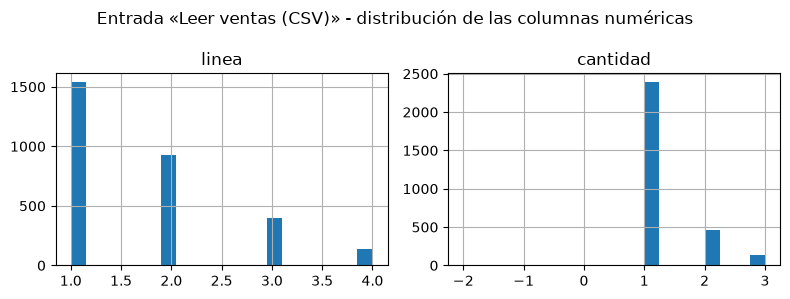

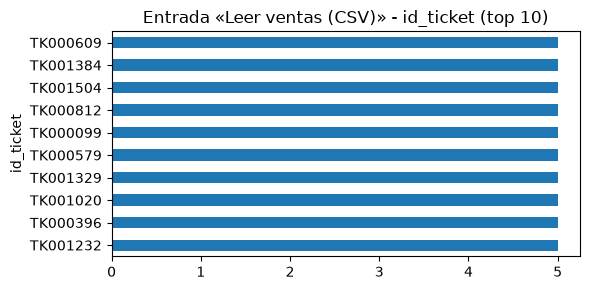

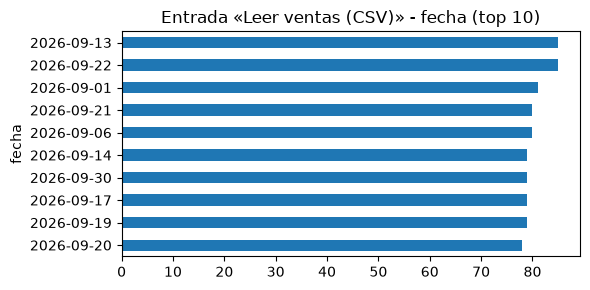

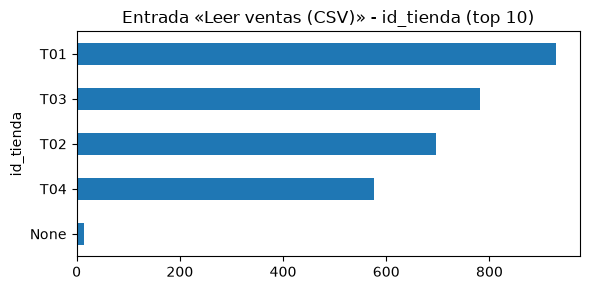

In [20]:
eda(df_leer_ventas_csv, "Entrada «Leer ventas (CSV)»")

### Entrada «Leer productos (Excel)»

== Entrada «Leer productos (Excel)»: 28 filas x 4 columnas
                   dtype  nulos
codigo_producto   object      0
nombre            object      0
categoria         object      0
precio_venta     float64      0
                count unique         top freq      mean       std  min  25%  \
codigo_producto    28     28     CAF-001    1       NaN       NaN  NaN  NaN   
nombre             28     28    Espresso    1       NaN       NaN  NaN  NaN   
categoria          28     14     Bebidas    4       NaN       NaN  NaN  NaN   
precio_venta     28.0    NaN         NaN  NaN  2.671429  0.885629  1.4  2.0   

                  50%  75%  max  
codigo_producto   NaN  NaN  NaN  
nombre            NaN  NaN  NaN  
categoria         NaN  NaN  NaN  
precio_venta     2.55  3.2  4.5  


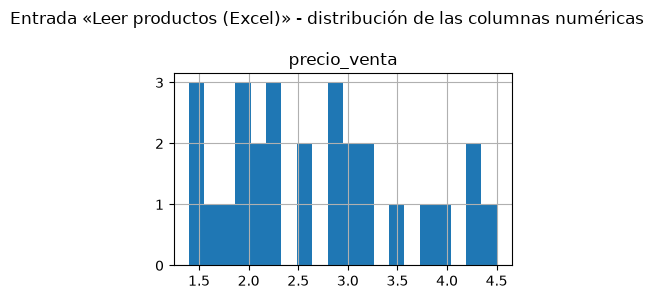

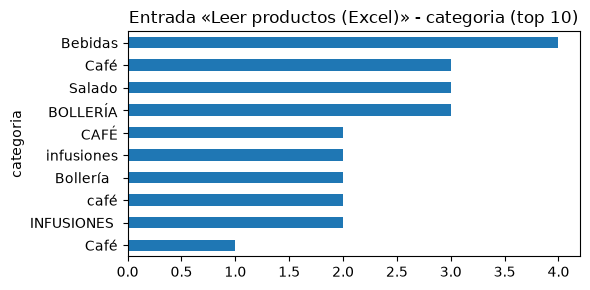

In [21]:
eda(df_leer_productos_excel, "Entrada «Leer productos (Excel)»")

### Entrada «Leer tiendas (JSON)»

In [22]:
eda(df_leer_tiendas_json, "Entrada «Leer tiendas (JSON)»")

== Entrada «Leer tiendas (JSON)»: 4 filas x 2 columnas
            dtype  nulos
id_tienda  object      0
nombre     object      0
          count unique       top freq
id_tienda     4      4       T01    1
nombre        4      4  Malasaña    1


### Salida «Escribir KPI»

== Salida «Escribir KPI»: 20 filas x 5 columnas
                         dtype  nulos
tienda                  object      0
categoria               object      0
unidades                 int64      0
importe_sin_redondear  float64      0
importe                float64      0
                      count unique       top freq     mean         std    min  \
tienda                   20      4  Chamberí    5      NaN         NaN    NaN   
categoria                20      5   Bebidas    4      NaN         NaN    NaN   
unidades               20.0    NaN       NaN  NaN   179.75  122.827168   59.0   
importe_sin_redondear  20.0    NaN       NaN  NaN  447.865  248.302386  149.8   
importe                20.0    NaN       NaN  NaN  447.865  248.302386  149.8   

                         25%    50%      75%     max  
tienda                   NaN    NaN      NaN     NaN  
categoria                NaN    NaN      NaN     NaN  
unidades                92.5  138.5    209.5   495.0  
importe_sin_redon

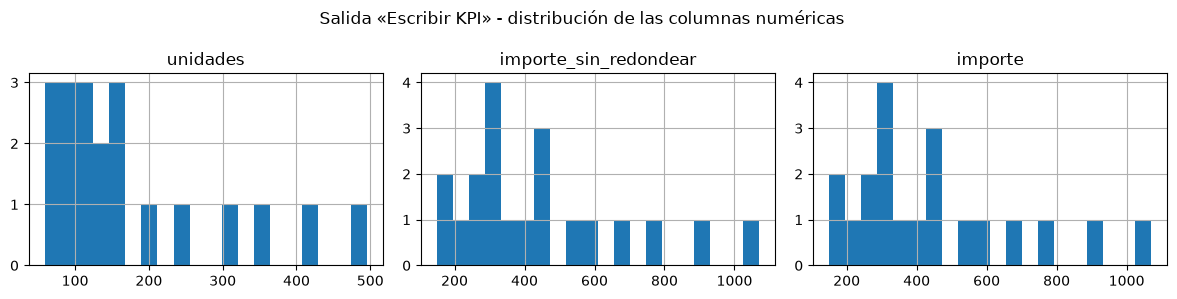

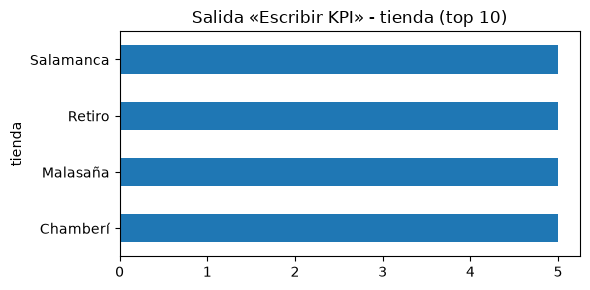

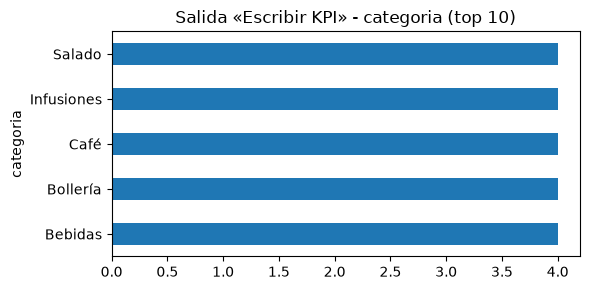

In [23]:
eda(df_escribir_kpi, "Salida «Escribir KPI»")

## Resumen

Steps: 17 (17 exactos, 0 aproximados, 0 a completar)

| # | Step | Tipo | Estado |
|---|---|---|---|
| 1 | Leer ventas (CSV) | `CsvInput` | exacto |
| 2 | Estandarizar textos | `StringOperations` | exacto |
| 3 | Normalizar precio | `ReplaceString` | exacto |
| 4 | Convertir precio a número | `SelectValues` | exacto |
| 5 | Leer productos (Excel) | `ExcelInput` | exacto |
| 6 | Ordenar por ticket y línea | `SortRows` | exacto |
| 7 | Leer tiendas (JSON) | `JsonInput` | exacto |
| 8 | Estandarizar productos | `StringOperations` | exacto |
| 9 | Eliminar duplicados | `Unique` | exacto |
| 10 | Buscar tienda | `StreamLookup` | exacto |
| 11 | Buscar categoría | `StreamLookup` | exacto |
| 12 | ¿Línea válida? | `FilterRows` | exacto |
| 13 | Calcular importe | `Calculator` | exacto |
| 14 | Ordenar por tienda y categoría | `SortRows` | exacto |
| 15 | Ventas por tienda y categoría | `GroupBy` | exacto |
| 16 | Redondear importe | `Calculator` | exacto |
| 17 | Escribir KPI | `TextFileOutput` | exacto |